# 02 — Do vetor ao índice de busca

Na etapa 01, cada trecho virou um embedding normalizado. Nesta etapa, esses vetores, textos e metadados são guardados no Chroma para que uma pergunta possa recuperar passagens relacionadas. Também se compara a busca aproximada HNSW com uma busca exata e se observa se MMR reduz trechos redundantes. O resultado alimenta o RAG da etapa 03.

```mermaid
flowchart LR
 A[dados_processados: chunks + vetores] --> B[Chroma persistente]
 B --> C[consulta: embedding da pergunta]
 C --> D[HNSW: candidatos aproximados]
 D --> E[ranking por cosseno]
 E --> F[MMR: diversidade opcional]
 F --> G[trechos para o RAG]
```

In [1]:
# Objetivo: definir diretórios do índice.
from pathlib import Path
import json

RANDOM_STATE = 42
DIRETORIO_PROJETO = Path.cwd()
if DIRETORIO_PROJETO.name != "Agente_IA_Transformers_Credito":
    DIRETORIO_PROJETO = DIRETORIO_PROJETO / "Agente_IA_Transformers_Credito"
if not DIRETORIO_PROJETO.is_dir():
    raise FileNotFoundError("Inicie o kernel na raiz do repositório ou na pasta do projeto.")

DIRETORIO_DOCUMENTOS = DIRETORIO_PROJETO / "documentos"
DIRETORIO_PROCESSADOS = DIRETORIO_PROJETO / "dados_processados"
DIRETORIO_RESULTADOS = DIRETORIO_PROJETO / "resultados"
DIRETORIO_PROCESSADOS.mkdir(exist_ok=True)
DIRETORIO_RESULTADOS.mkdir(exist_ok=True)
print("Projeto:", DIRETORIO_PROJETO)

Projeto: d:\Projetos_v2\Agente_IA_Transformers_Credito


## 1. Carregar os vetores e preparar a consulta

O manifesto, os textos e os embeddings vêm da etapa 01. A checagem confirma que há um vetor para cada trecho e que os vetores armazenados têm norma aproximadamente 1. Usa-se o mesmo encoder para transformar a pergunta: trocar o encoder mudaria o espaço em que documentos e consulta são comparados.

### Similaridade de cosseno: o que mede

A similaridade de cosseno mede o alinhamento entre as direções de dois vetores. Para consulta $q$ e trecho $x$:

$$
\operatorname{sim}_{\cos}(q,x)=\frac{q^T x}{\|q\|_2\,\|x\|_2},
\qquad d_{\cos}(q,x)=1-\operatorname{sim}_{\cos}(q,x).
$$

Como os embeddings dos documentos e da pergunta são normalizados, as duas normas valem 1. Assim, a similaridade pode ser calculada apenas pelo produto escalar $q^T x$. Por exemplo, para $q=[1,0]$, $a=[0{,}8,0{,}6]$ e $b=[0,1]$, obtêm-se similaridades 0,8 e 0, respectivamente; o trecho $a$ fica antes de $b$. Esses vetores são apenas didáticos.

No Chroma, `space="cosine"` define a métrica do índice. Distância menor significa maior proximidade segundo o encoder, mas não mede relevância humana, verdade ou probabilidade de uma resposta estar correta. Por isso, inspecionam-se também o texto e a fonte recuperados.

In [2]:
# Objetivo: carregar e validar chunks e embeddings.
import hashlib
import json
import numpy as np
from sentence_transformers import SentenceTransformer

manifesto = json.loads((DIRETORIO_PROCESSADOS / "manifesto_corpus.json").read_text(encoding="utf-8"))
chunks = [json.loads(linha) for linha in (DIRETORIO_PROCESSADOS / "chunks.jsonl").read_text(encoding="utf-8").splitlines() if linha]
vetores = np.load(DIRETORIO_PROCESSADOS / "embeddings.npy")
NOME_ENCODER = manifesto["encoder"]
assert len(chunks) == len(vetores) == manifesto["quantidade_chunks"]
assert np.allclose(np.linalg.norm(vetores[:20], axis=1), 1.0, atol=1e-4)
encoder = SentenceTransformer(NOME_ENCODER, device="cpu")
print("Chunks e embeddings carregados:", vetores.shape)

c:\Users\leova\anaconda3\envs\engenharia_ia_venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4230.23it/s]


Chunks e embeddings carregados: (990, 384)


## 2. Criar ou atualizar a coleção persistente

A coleção associa cada ID estável ao texto, ao embedding e aos metadados, como documento e página. `upsert` insere um ID novo ou atualiza o registro com o mesmo ID; em seguida, removem-se IDs que não pertencem mais ao corpus atual. Isso permite reexecutar a etapa sem acumular cópias ou deixar trechos obsoletos.

### Como o HNSW encontra candidatos

Comparar a pergunta com cada um dos $N$ vetores exige calcular $N$ similaridades. Essa busca exata é simples e serve de referência, mas o trabalho cresce com o tamanho do corpus. HNSW (Hierarchical Navigable Small World) organiza vetores em um grafo de vizinhos com camadas: camadas mais esparsas ajudam a chegar rapidamente a uma região; camadas mais densas refinam a busca local. O algoritmo visita uma parte do grafo, então pode não retornar exatamente os mesmos vizinhos que a busca exata.

Na configuração deste notebook, `max_neighbors=16` limita conexões por nó, `ef_construction=100` controla o esforço de construção do índice e `ef_search=100` controla o esforço de exploração durante a consulta. `n_results` (ou $k$) define quantos resultados são devolvidos; `ef_search` afeta quantos candidatos são explorados para encontrá-los. Aumentar o esforço pode melhorar a recuperação e elevar a latência, mas não garante ganho em qualquer corpus.

A coleção é persistente: ela continua disponível após encerrar o processo. Conferir sua contagem e reabri-la em outro processo verifica que o artefato foi gravado e pode ser usado pela etapa seguinte.

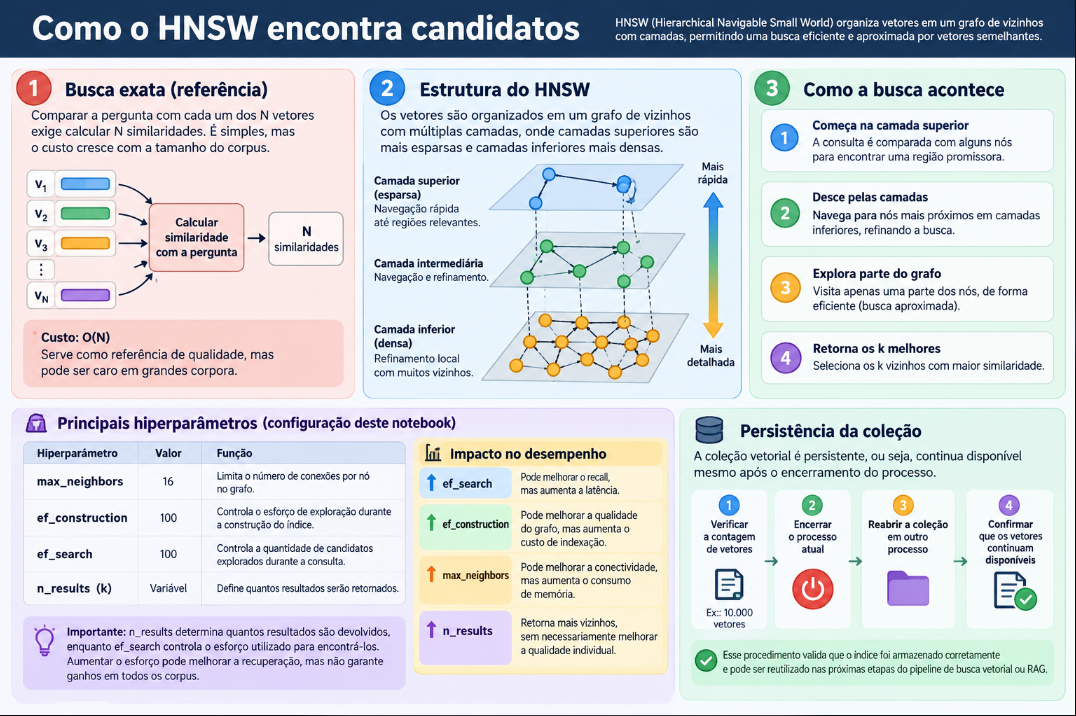

In [3]:
# Objetivo: persistir os vetores na coleção Chroma.
import chromadb
# PersistentClient abre ou cria o banco local no caminho informado.
cliente = chromadb.PersistentClient(path=str(DIRETORIO_PROJETO / "banco_chroma"))
# Abre ou cria a coleção; nome identifica o corpus, configuration ajusta HNSW e metadata registra o encoder.
colecao = cliente.get_or_create_collection(
    "transformers_credito_v1",
    configuration={"hnsw": {"space": "cosine", "max_neighbors": 16, "ef_construction": 100, "ef_search": 100}},
    metadata={"encoder": NOME_ENCODER},
)
assert colecao.metadata["encoder"] == NOME_ENCODER
ids_atuais = [c["id"] for c in chunks]
for inicio in range(0, len(chunks), 100):
    lote = chunks[inicio:inicio+100]
    # upsert insere ou atualiza registros: ids identificam, documents guardam texto, embeddings guardam vetores e metadatas guardam origem.
colecao.upsert(
        ids=[c["id"] for c in lote], documents=[c["texto"] for c in lote],
        embeddings=vetores[inicio:inicio+100].tolist(),
        metadatas=[{k:v for k,v in c.items() if k not in ["id", "texto"]} for c in lote],
    )
obsoletos = sorted(set(colecao.get()["ids"]) - set(ids_atuais))
if obsoletos:
    colecao.delete(ids=obsoletos)
assert colecao.count() == len(chunks)
print("Registros persistidos:", colecao.count())
print("Configuração:", colecao.configuration)

Registros persistidos: 990
Configuração: {'hnsw': {'space': 'cosine', 'ef_construction': 100, 'ef_search': 100, 'max_neighbors': 16, 'resize_factor': 1.2, 'sync_threshold': 1000}, 'spann': None, 'embedding_function': <chromadb.api.types.DefaultEmbeddingFunction object at 0x000001E47ACE7D00>}


## 3. Comparar busca exata e HNSW; depois observar MMR

A busca exata ordena todos os vetores por similaridade com a pergunta. HNSW é comparado com esse ranking por meio do Recall ANN@k:

$$
\operatorname{Recall}_{ANN}@k = \frac{|IDs_{HNSW}@k \cap IDs_{exatos}@k|}{k}.
$$

Se os três vizinhos exatos forem $\{A,B,C\}$ e HNSW retornar $\{A,C,D\}$, então Recall ANN@3 = $2/3$. A medida informa quanto o índice aproximado reproduz os vizinhos da busca exata para aquela consulta. Não avalia se esses vizinhos contêm a evidência necessária; isso exige perguntas representativas e revisão do conteúdo.

### MMR: equilibrar relevância e diversidade

MMR (Maximal Marginal Relevance) reordena um conjunto de candidatos: tenta escolher passagens relevantes para a pergunta que também tragam informação diferente das já selecionadas. A regra usada em `rag.py` é:

$$
\operatorname{MMR}(x_i)=\lambda\,\operatorname{sim}(q,x_i) - (1-\lambda)\max_{x_j\in S}\operatorname{sim}(x_i,x_j),
$$

em que $q$ é a pergunta, $S$ é o conjunto de passagens já escolhidas e $\lambda$ equilibra relevância e redundância. O código usa $\lambda=0{,}7$: dá mais peso à relevância, mas ainda penaliza candidatos muito parecidos com os escolhidos. O primeiro candidato é o mais relevante; a regra é aplicada nas escolhas seguintes.

Exemplo: se dois chunks quase repetem a mesma definição, MMR pode preferir o segundo chunk que explica uma limitação ou apresenta um exemplo. Isso pode ampliar a cobertura do contexto, mas também pode descartar uma passagem repetida que contenha um detalhe útil. MMR é uma alternativa a avaliar, não uma melhoria presumida. Aqui, HNSW busca `fetch_k=12` candidatos e MMR seleciona até $k=4$; a inspeção lado a lado mostra o efeito concreto.

In [4]:
# Objetivo: comparar busca aproximada e exata e inspecionar MMR.
import sys
import inspect
if str(DIRETORIO_PROJETO) not in sys.path:
    sys.path.insert(0, str(DIRETORIO_PROJETO))
from rag import selecionar_mmr, recuperar, montar_mensagens
print(inspect.getsource(selecionar_mmr))

pergunta_rag = "Como a atenção pode representar sequências e quais cuidados existem na previsão de inadimplência de consumidores?"
vetor_consulta = encoder.encode(pergunta_rag, normalize_embeddings=True)
similaridades = vetores @ vetor_consulta
indices_exatos = np.argsort(-similaridades)[:4]
# query consulta o índice aproximado; query_embeddings recebe o vetor da pergunta e n_results limita vizinhos retornados.
resultado_ann = colecao.query(query_embeddings=[vetor_consulta.tolist()], n_results=4)
ids_exatos = {chunks[i]["id"] for i in indices_exatos}
recall_ann = len(ids_exatos.intersection(resultado_ann["ids"][0])) / 4
print("Recall ANN@4 desta consulta:", recall_ann)
# recuperar codifica a pergunta, busca candidatos e retorna trechos; k limita a saída e fetch_k define candidatos para MMR.
trechos = recuperar(colecao, encoder, pergunta_rag, usar_mmr=True, k=4, fetch_k=12)
for trecho in trechos:
    print(trecho["source_id"], "página", trecho["page"], trecho["texto"][:250])

def selecionar_mmr(vetores, consulta, k=4, peso=0.7):
    """Seleciona candidatos normalizados por relevância menos redundância."""
    vetores = np.asarray(vetores, dtype=np.float32)
    consulta = np.asarray(consulta, dtype=np.float32)
    if len(vetores) == 0:
        return []
    relevancia = vetores @ consulta
    escolhidos = [int(np.argmax(relevancia))]
    while len(escolhidos) < min(k, len(vetores)):
        redundancia = (vetores @ vetores[escolhidos].T).max(axis=1)
        scores = peso * relevancia - (1 - peso) * redundancia
        scores[escolhidos] = -np.inf
        escolhidos.append(int(np.argmax(scores)))
    return escolhidos

Recall ANN@4 desta consulta: 1.0
attention_is_all_you_need página 2 ]. In the Transformer this is reduced to a constant number of operations, albeit at the cost of reduced effective resolution due to averaging attention-weighted positions, an effect we counteract with Multi-Head Attention as described in section 3.2.
consumer_default página 19 

## 4. Checkpoint: do índice para a geração

A coleção deve devolver texto, ID e metadados de procedência, como título e página. A etapa 03 envia os trechos recuperados ao Qwen e apresenta as fontes. Essa separação ajuda a investigar erros: a evidência pode não ter sido recuperada, pode ter chegado incompleta ao prompt ou pode ter sido interpretada incorretamente pelo gerador.

Um Recall ANN@4 perfeito em uma única consulta mostra apenas que HNSW coincidiu com a busca exata nesse caso. Para comparar configurações, é preciso usar várias perguntas anotadas, medir a qualidade das evidências recuperadas e acompanhar latência e memória. A busca exata é referência de vizinhos, não um gabarito de qualidade semântica.